In [1]:
#Import all necessary library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
#Load the dataset
df = pd.read_csv(
    "AirQuality.csv",
    sep=";", #tells pandas to separate columns using semicolons
    decimal=","
)

print("Dataset Shape:", df.shape)
display(df.head())
print(df.info())

Dataset Shape: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), str(2)
memory usage: 1.4 MB
None


In [4]:
#remove unnessary column
df = df.drop(
    columns=["Unnamed: 15", "Unnamed: 16"],
    errors="ignore"
)

display(df.head())

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [5]:
# Convert relevant columns to numeric
columns_to_convert = ["CO(GT)", "C6H6(GT)", "T", "RH", "AH"]

for col in columns_to_convert:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Replace -200 with NaN
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].replace(-200, np.nan)

print(df.dtypes)

Date                 str
Time                 str
CO(GT)           float64
PT08.S1(CO)      float64
NMHC(GT)         float64
C6H6(GT)         float64
PT08.S2(NMHC)    float64
NOx(GT)          float64
PT08.S3(NOx)     float64
NO2(GT)          float64
PT08.S4(NO2)     float64
PT08.S5(O3)      float64
T                float64
RH               float64
AH               float64
dtype: object


**Split the Data into Training and Testing Sets**

In [6]:
random_seed = 42

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=random_seed
)

print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)

Training Dataset: (7576, 15)
Testing Dataset: (1895, 15)


**Handle Missing values**


In [7]:
# Check missing values before cleaning
print("Training Missing Values:")
print(train_df.isnull().sum())

print("\nTesting Missing Values:")
print(test_df.isnull().sum())

# Drop rows containing missing values
train_df = train_df.dropna().copy()
test_df = test_df.dropna().copy()

print("\nTraining Shape After Cleaning:", train_df.shape)
print("Testing Shape After Cleaning:", test_df.shape)

Training Missing Values:
Date               92
Time               92
CO(GT)           1466
PT08.S1(CO)       390
NMHC(GT)         6857
C6H6(GT)          390
PT08.S2(NMHC)     390
NOx(GT)          1424
PT08.S3(NOx)      390
NO2(GT)          1427
PT08.S4(NO2)      390
PT08.S5(O3)       390
T                 390
RH                390
AH                390
dtype: int64

Testing Missing Values:
Date               22
Time               22
CO(GT)            331
PT08.S1(CO)        90
NMHC(GT)         1700
C6H6(GT)           90
PT08.S2(NMHC)      90
NOx(GT)           329
PT08.S3(NOx)       90
NO2(GT)           329
PT08.S4(NO2)       90
PT08.S5(O3)        90
T                  90
RH                 90
AH                 90
dtype: int64

Training Shape After Cleaning: (652, 15)
Testing Shape After Cleaning: (175, 15)


**Create the binary target variable**

In [8]:
# Calculate median using training data only
median_co = train_df["CO(GT)"].median()

print("Training Median CO:", median_co)

# Create target in both datasets
train_df["CO_Level"] = (
    train_df["CO(GT)"] > median_co
).astype(int)

test_df["CO_Level"] = (
    test_df["CO(GT)"] > median_co
).astype(int)

print("\nTraining Target Distribution:")
print(train_df["CO_Level"].value_counts())

print("\nTesting Target Distribution:")
print(test_df["CO_Level"].value_counts())

Training Median CO: 2.1

Training Target Distribution:
CO_Level
0    336
1    316
Name: count, dtype: int64

Testing Target Distribution:
CO_Level
0    100
1     75
Name: count, dtype: int64


**Feature and Target Definition**

In [9]:
# Define features
X_train = train_df.drop(
    columns=["Date", "Time", "CO(GT)", "CO_Level"]
)

X_test = test_df.drop(
    columns=["Date", "Time", "CO(GT)", "CO_Level"]
)

# Define targets
y_train = train_df["CO_Level"]
y_test = test_df["CO_Level"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (652, 12)
X_test: (175, 12)
y_train: (652,)
y_test: (175,)


In [10]:
#Apply feature scaling
scaler = StandardScaler()

# Fit and transform training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing features
X_test_scaled = scaler.transform(X_test)

**Implementing the k-NN Classification Model**

In [11]:
k_values = range(1, 31)
accuracy_scores = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    # Train model
    knn.fit(X_train_scaled, y_train)

    # Predict test labels
    y_pred = knn.predict(X_test_scaled)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    accuracy_scores.append(accuracy)

    print(f"k = {k}, Accuracy = {accuracy:.4f}")

k = 1, Accuracy = 0.9429
k = 2, Accuracy = 0.9600
k = 3, Accuracy = 0.9543
k = 4, Accuracy = 0.9714
k = 5, Accuracy = 0.9543
k = 6, Accuracy = 0.9714
k = 7, Accuracy = 0.9657
k = 8, Accuracy = 0.9600
k = 9, Accuracy = 0.9543
k = 10, Accuracy = 0.9657
k = 11, Accuracy = 0.9600
k = 12, Accuracy = 0.9486
k = 13, Accuracy = 0.9429
k = 14, Accuracy = 0.9543
k = 15, Accuracy = 0.9543
k = 16, Accuracy = 0.9543
k = 17, Accuracy = 0.9429
k = 18, Accuracy = 0.9543
k = 19, Accuracy = 0.9486
k = 20, Accuracy = 0.9486
k = 21, Accuracy = 0.9429
k = 22, Accuracy = 0.9429
k = 23, Accuracy = 0.9429
k = 24, Accuracy = 0.9429
k = 25, Accuracy = 0.9429
k = 26, Accuracy = 0.9486
k = 27, Accuracy = 0.9486
k = 28, Accuracy = 0.9486
k = 29, Accuracy = 0.9429
k = 30, Accuracy = 0.9486


**Plot accuracy against k**

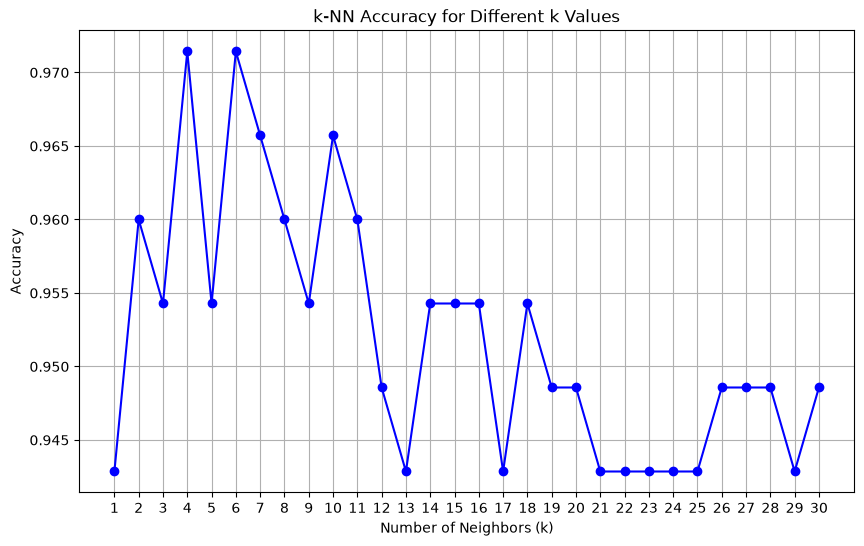

In [12]:
plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    accuracy_scores,
    marker="o",
    linestyle="-",
    color="blue"
)

plt.title("k-NN Accuracy for Different k Values")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")

plt.xticks(range(1, 31))
plt.grid(True)
plt.show()

**Find the optimal k**

In [13]:
best_k = list(k_values)[np.argmax(accuracy_scores)]
best_accuracy = max(accuracy_scores)

print("Optimal k:", best_k)
print(f"Highest Accuracy: {best_accuracy:.4f}")

Optimal k: 4
Highest Accuracy: 0.9714


**Confusion Matrix and Classification Report**

Classification Report:
              precision    recall  f1-score   support

      Low CO       0.97      0.98      0.98       100
     High CO       0.97      0.96      0.97        75

    accuracy                           0.97       175
   macro avg       0.97      0.97      0.97       175
weighted avg       0.97      0.97      0.97       175



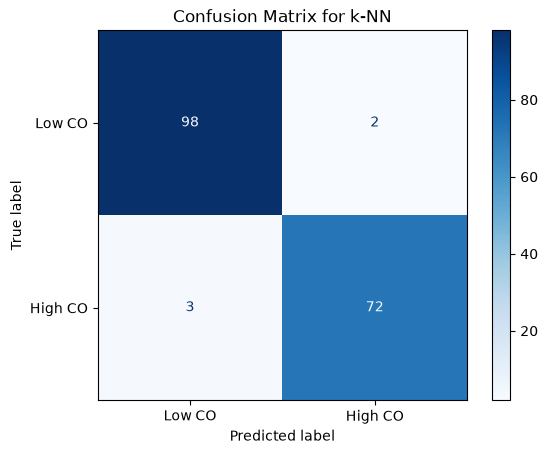

In [14]:
best_knn = KNeighborsClassifier(n_neighbors=best_k)

best_knn.fit(X_train_scaled, y_train)

y_pred_best = best_knn.predict(X_test_scaled)

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=["Low CO", "High CO"]
))

cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low CO", "High CO"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix for k-NN")
plt.show()

The k-Nearest Neighbors (k-NN) classification model achieved an overall accuracy of approximately 97.14%, indicating high performance in classifying carbon monoxide (CO) concentrations as Low or High.

For precision, the model achieved 97% precision for both Low and High CO levels, indicating that most predictions in each category were correct
For recall, the model correctly identified 98% of actual Low CO observations and 96% of actual High CO observations.
For f1-score, the scores of 0.98 for Low CO and 0.97 for High CO demonstrate a strong balance between precision and recall.


Also, the model correctly classified 98 observation as Low CO and 72 as high CO. However, teh model wrongly clasify2 observation as high and 3 observations as low.

The optimum K value is the point where accuracy is highest which is k=4 with 97.14%accuracy